# 03-任务调度器与上下文保护

> 调度器决定“下一个运行谁”，上下文切换负责“让它带着原来的状态继续运行”。换对 SP、回到正确地址，只完成了后一个要求的一部分。

这是《自己动手写嵌入式操作系统》五篇笔记中的第 03 篇。第 02 篇已经解释初始任务栈、SP 与 RET，本篇继续分析轮转调度及任务切换时的上下文混淆。


## 1. 本篇范围与资料说明

| 视频 | 已核对的目录标题 | 本篇重点 |
|---|---|---|
| 14 | 任务调度器的实现 | 保存当前 SP、任务编号轮转、恢复目标 SP |
| 15 | 任务切换的上下文混淆问题 | 寄存器、返回帧与 C51 数据存储的约束 |

**已核对资料：**课程网盘的视频目录，以及 `代码/os_demo.zip` 中的 `main.c`、`Listings/main.lst`、`Listings/project.m51`、`project.uvproj` 和 `Objects/project.hex`。工程目标为 **STC8H8K64U Series**；包内编译记录为 C51 V9.60.7.0，链接结果使用 SMALL 模型和 `RAMSIZE(256)`。

视频未逐段观看或转录。本篇的代码和地址来自配套综合示例与包内已有编译结果；原理、故障例子、示意图和改进思路标为补充内容。本篇没有重新编译，也没有进行模拟器或硬件运行验证。

**版本边界：**压缩包已包含后续的 `sleep` 和定时器代码，不是第 14、15 节每个阶段的独立快照。因此，不能把下面的静态分析写成“老师在这一节已经完成了某个修复”。


## 2. 先分清调度策略和切换机制

以下为**补充理解**。

| 问题 | 对应职责 | 本例中的表达 |
|---|---|---|
| 接下来选择哪个任务？ | 调度策略 | `task_id` 加一，到末尾回到零 |
| 当前任务以后从哪里继续？ | 返回位置保存 | 当前调用链中的返回地址留在任务栈里 |
| 目标任务使用哪份栈？ | 栈切换 | 保存当前 SP，再装入目标 SP |
| 目标任务的中间结果是什么？ | 上下文保护 | 还需按入口与工具链约定保存、恢复相关状态 |

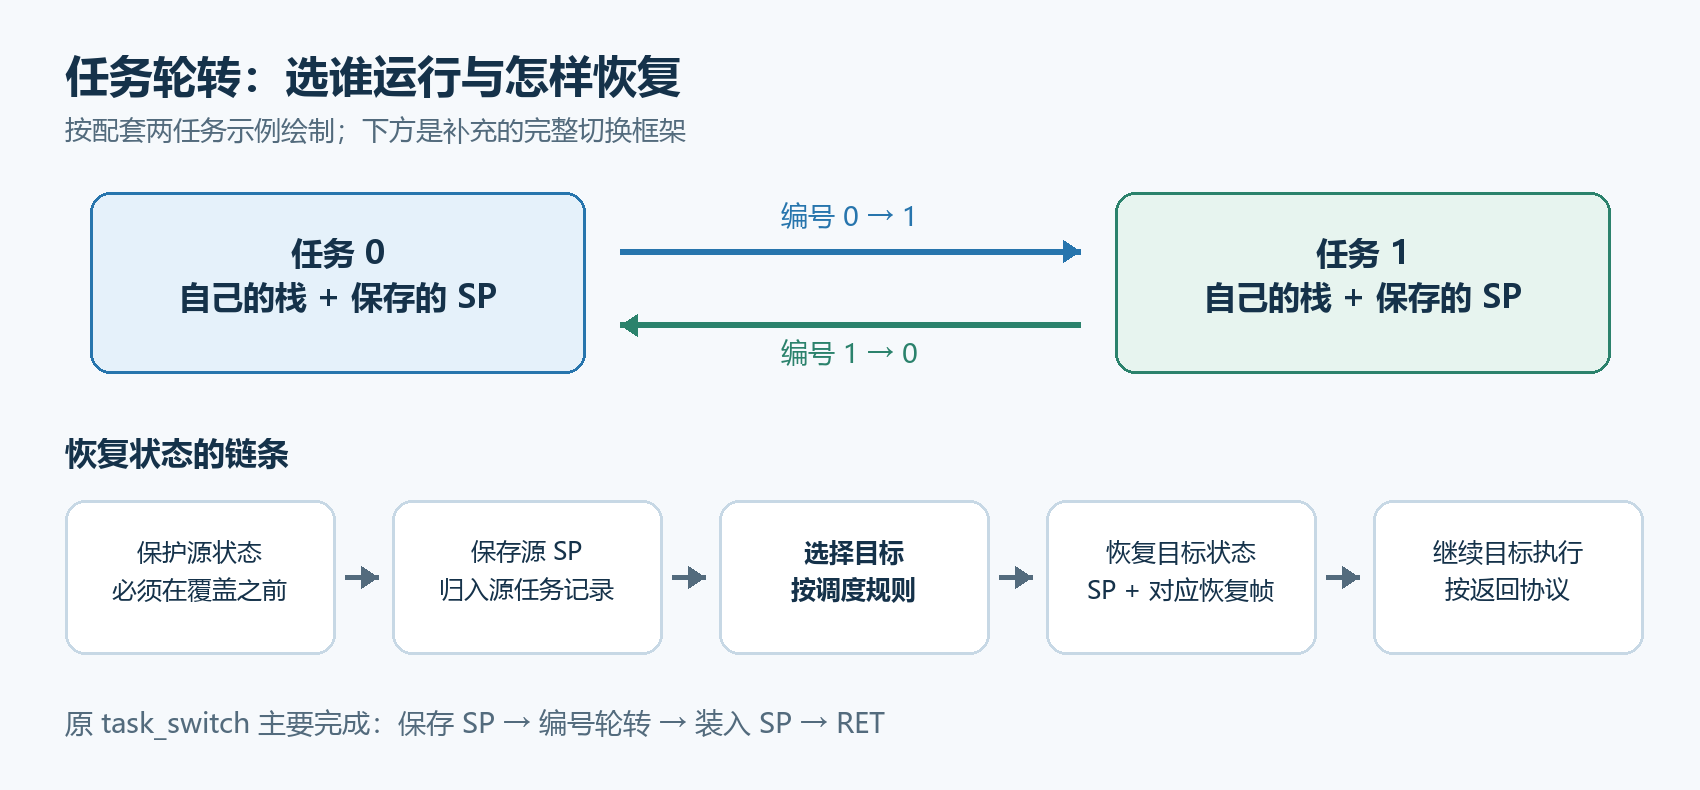

*自绘补充示意图。图中的“保护/恢复状态”是完整切换需要考虑的步骤，不表示配套 `task_switch` 已实现这些动作。*

两个概念可以分别验证：任务编号顺序正确，但寄存器可能错误；寄存器保存完整，但选择了不该运行的任务，也仍然有问题。


## 3. 配套 task_switch 的实际代码

下面是 `os_demo/main.c` 的**源码摘录**，仅去掉注释并统一空白：

```c
#define MAX_TASKS 2
#define MAX_TASK_DEP 32

unsigned char idata task_sp[MAX_TASKS];
unsigned char idata task_stack[MAX_TASKS][MAX_TASK_DEP];
unsigned char task_id;

void task_switch(){
    task_sp[task_id] = SP;
    task_id = task_id + 1;
    if(task_id == MAX_TASKS){
        task_id = 0;
    }
    SP = task_sp[task_id];
}
```

这里的 `task_sp` 保存各任务的栈顶位置，`task_stack` 是每个任务实际的栈区域。`idata` 是 Keil C51 的存储空间限定词，不是标准 C 关键字。

这段函数同时做了简单选择和换栈，但没有显式保存 ACC、PSW 或整组通用寄存器，也没有检查目标任务是否挂起。


## 4. 四个动作为什么必须按顺序完成？

| 动作 | 源码 | 目的 |
|---|---|---|
| 1. 保存源任务 SP | `task_sp[task_id] = SP` | 留下当前栈顶部的位置 |
| 2. 递增任务编号 | `task_id = task_id + 1` | 选择后一项 |
| 3. 编号回绕 | 到 `MAX_TASKS` 时置零 | 形成循环 |
| 4. 使用目标 SP | `SP = task_sp[task_id]` | 让后续返回指令使用目标栈 |

**补充推演：**假设当前为任务 0，SP=`0x16`，任务 1 保存的 SP=`0x36`：

```text
保存前：task_id=0，硬件 SP=0x16
保存后：task_sp[0]=0x16
选择后：task_id=1
换栈后：硬件 SP=0x36
随后 RET：从任务1的栈取回地址
```

如果先把 `task_id` 改为 1，再保存 SP，就会把任务 0 的位置写进任务 1 的记录。如果先恢复目标 SP，再保存源任务 SP，也会保存错误的值。

**切换中的不一致窗口：**编号已经改为目标任务、SP 还属于源任务时，二者暂时不一致。若允许会再次调度的中断在这里进入，可能把栈记录归给错误任务。更完整的实现必须管理这个窗口，不能只看四行 C 语句的顺序。


## 5. 轮转顺序正确，不等于每个任务时间相同

本例的编号变化为：

| 当前编号 | 加一后的值 | 回绕后的目标编号 |
|---|---|---|
| 0 | 1 | 1 |
| 1 | 2 | 0 |

```text
0 → 1 → 0 → 1 → ……
```

**补充理解：**这是一种按固定顺序轮转的选择规则，但在任务主动调用 `task_switch` 的路径上，每次运行多久取决于任务何时让出 CPU。它不自动带来固定时间片。

自编例子：任务 0 每次计算 1 ms 后让出，任务 1 每次计算 100 ms 后让出。编号仍严格交替，CPU 时间却明显不均等。某个任务若一直不让出，单靠这种协作路径不能迫使它切换。

本例 `task_switch` 也没有筛选就绪任务。综合源码由任务自己检查 `TASK_SUSPENDED`，挂起时立即再次调用切换函数。这和内核在就绪队列中直接选择可运行任务不同；两个任务都等待时，仍可能不断轮流执行检查与让出代码。等待与 `sleep` 的具体实现留到第 05 篇。


## 6. 栈中保存的是“继续位置”

接着第 02 篇的已核对编译结果：任务 0 的一处普通调用在 CODE `0x01AE`，任务 1 的一处普通调用在 `0x0140`；两处都是三字节 `LCALL task_switch`。

| 任务 | 调用地址 | 调用后的继续位置 | 对应返回地址字节 |
|---|---|---|---|
| 0 | `0x01AE` | `0x01B1` | 低字节 `0xB1`、高字节 `0x01` |
| 1 | `0x0140` | `0x0143` | 低字节 `0x43`、高字节 `0x01` |

**简化推演，忽略中断和其他上下文：**A 调用切换函数时，A 的继续地址已被 CALL 压入 A 栈。保存 A 的 SP，再恢复 B 的 SP，切换函数末尾的 RET 就使用 B 栈。

- B 尚未运行：B 栈里是 `task_load` 构造的任务入口。
- B 曾在普通调用处让出：B 栈里是上次调用后的继续位置。
- B 在中断路径中被切出：顶部可能首先是 ISR 内部调用的返回位置，下面还有别的帧，不能按前两种情况直接理解。

仅重建入口帧会让任务反复从头开始；正确恢复已保存的栈，才有机会接着运行。


## 7. 从机器码看 task_switch 改动了什么

包内 `project.m51` 把 `task_switch` 定位在 CODE `0x01D3—0x01EC`。下面是对 `project.hex` 中对应字节的**静态指令解读**：

```asm
; task_id 在内部 RAM 08H，task_sp 首地址是 55H
01D3: MOV  A,#055H
01D5: ADD  A,08H
01D7: MOV  R0,A
01D8: MOV  @R0,SP       ; 保存当前 SP
01DA: INC  08H         ; task_id++
01DC: MOV  A,08H
01DE: CJNE A,#02H,01E4H
01E1: CLR  A
01E2: MOV  08H,A       ; 到末尾时回到任务0
01E4: MOV  A,#055H
01E6: ADD  A,08H
01E8: MOV  R0,A
01E9: MOV  A,@R0
01EA: MOV  SP,A        ; 恢复目标 SP
01EC: RET
```

完整对应字节：

```text
74 55 25 08 F8 A6 81 05 08 E5 08 B4 02 03
E4 F5 08 74 55 25 08 F8 E6 F5 81 22
```

由此可以直接看出：

| 对象 | 本次生成代码的变化 |
|---|---|
| ACC，也写作 A | 用于计算地址和读取目标 SP，原值被覆盖 |
| R0 | 用于访问 `task_sp`，原值被覆盖 |
| PSW 中的相关标志 | ADD、CJNE 等影响标志，不能认为原状态保持 |
| `task_id`、`task_sp`、SP | 按调度与换栈逻辑更新 |

本段没有 PUSH/POP 寄存器保护代码。**注意：**普通 C 调用可以按调用约定允许某些寄存器被覆盖，不能据此认定任何函数都必须原样恢复全部寄存器；任务切换和任意位置的抢占还要满足更强的恢复条件。

这些地址只属于包内这次编译。改变源码、编译选项或布局后，应重新查看生成结果。


## 8. 任务上下文到底包含哪些信息？

以下为**补充理解**，针对经典 8051 兼容模型；实际端口需结合器件与工具链。

| 状态 | 作用 | 丢失后可能的结果 |
|---|---|---|
| PC 或能恢复 PC 的返回链 | 继续执行的位置 | 跑到错误代码 |
| SP 与栈内容 | 找到正确调用链和保存帧 | 返回地址或恢复数据错位 |
| ACC | 运算与传送的中间值 | 计算结果改变 |
| B | 乘除法及工具链使用的中间状态 | 乘除结果或临时值改变 |
| PSW | 进位等标志及寄存器组选择 | 多字节运算、后续寄存器访问错误 |
| R0—R7 | 临时值、参数、循环变量等 | 任务的数据相互混入 |
| DPTR，经典模型中的 DPL/DPH | 数据或代码空间访问的指针 | 访问到错误位置 |
| 工具链或增强内核的额外状态 | 例如软件栈指针、额外 DPTR 的选择状态 | 仅保存经典寄存器仍可能不足 |

需要保存的是恢复任务所必需的状态。PC 往往已由调用或中断压栈保存；SP 通常单独记录，不要求“把所有对象再额外压一遍”。外设状态是否按任务隔离，则是另一项设计问题，第 04 篇继续讨论。

判断标准应是：恢复以后，任务接着执行时所依赖的状态，与它被暂停时相符。


## 9. 自编故障例子：地址正确，进位却丢了

下面是**补充故障推演**，不是配套工程的实测结果。假设一个任务在计算 `0x12FF + 1`，低字节计算完成，高字节还没计算：

```text
低字节：0xFF + 0x01 = 0x00，产生进位 CY=1
高字节应为：0x12 + 0x00 + CY = 0x13
正确结果：0x1300
```

如果此时被抢占，另一任务把 CY 改为 0；恢复时只恢复执行位置，没有恢复需要的 PSW 状态，并假设其他操作数保持不变：

```text
恢复后仍执行原来的高字节加法
高字节变成：0x12 + 0x00 + 0 = 0x12
错误结果：0x1200
```

这里没有跑错地址，也没有“从函数开头重新执行”，却算出了错误结果。这就是理解上下文混淆的关键：**位置正确和状态正确需要分别成立。**

对应到指令概念，低字节 ADD 与高字节 ADDC 之间的进位标志也属于需要保护的执行状态。正常 ISR 若完整恢复它所破坏的状态，可以避免这种干扰；改变栈和恢复路径以后，必须重新检查这种保证是否仍成立。


## 10. C 局部变量不一定在任务私有栈上

这是 C51 与很多桌面 C 环境容易混淆的地方，下面结合**实际链接表和机器码**说明。

配套源码中 `Delay1000ms` 声明：

```c
unsigned char i, j, k;
```

包内 `project.m51` 将它们标在内部地址 `0x07`、`0x06`、`0x05`。对应函数的机器码使用 R7、R6、R5，例如：

```asm
MOV R7,#07AH     ; i = 122
MOV R6,#0C1H     ; j = 193
MOV R5,#080H     ; k = 128
; 后续循环对这些寄存器执行 DJNZ
```

在本次寄存器组 0 的布局下，这三个地址对应 R7、R6、R5。它们不是因为函数里写了局部变量，就自动放进 `task_stack[0]` 或 `task_stack[1]`。

**补充理解：**Keil C51 的非重入函数还可能把参数或局部数据放在固定区域，并对互不同时活动的函数使用存储覆盖。包内编译清单标明模块为 `STATIC OVERLAYABLE`。动态任务切换可能打破普通调用树的同时活动假设；应结合函数的具体数据分配与重入配置判断。

也不能把 `static` 当作完整解决办法：它只改变存储期；同一个函数的一份静态变量仍然可能被多个调用者共享。

配套任务函数中的 `static unsigned int a/b` 和 `Delay1000ms()` 调用目前都被注释掉。本篇不会把这些未执行语句的现象当作当前源码的运行结果。延时问题留给第 04 篇分析。


## 11. 普通函数调用和任务暂停的保护要求不同

以下为**补充理解**。

| 场景 | 编译器通常知道什么 | 需要检查什么 |
|---|---|---|
| 普通 C 函数调用 | 调用位置与函数调用约定 | 哪些寄存器由调用者或被调用者负责 |
| 主动让出的协作任务 | 让出发生在明确调用位置 | 调用约定、任务栈、跨任务的数据隔离 |
| 任意指令位置被中断抢占 | 暂停点可能位于运算中间 | 被暂停任务仍在使用的全部必要状态 |

所以，“函数改变 A”对普通调用可能完全合法；“暂停后没有恢复任务正在使用的 A”对抢占恢复则可能错误。

协作调度能利用明确让出位置与调用约定减少保存工作，但这必须有明确的端口设计和编译结果依据。不能把“这个例子暂时没有用到某个寄存器”，推广成“永远不需要保存它”。

C51 的普通调用约定也不自动提供任务间重入保证。即使寄存器全部保存了，共用的参数区、固定局部数据或共享对象仍可能被另一任务覆盖。


## 12. 普通调用与中断调用：源码中的两条入口

配套任务在循环中主动调用 `task_switch()`；同时，源码还定义了：

```c
void Timer1_ISR(void) interrupt 3{
    task_switch();
}
```

这是**源码摘录**。`interrupt 3` 是 C51 的中断函数声明，在本工程中对应定时器 1 的中断向量。

| 入口 | 怎样到达切换函数 | 是否天然有中断返回帧 |
|---|---|---|
| 任务主动调用 | 普通 CALL | 没有，仅有普通调用链 |
| Timer1 ISR 调用 | 硬件中断 → ISR → CALL | 有硬件返回地址、ISR 保存数据，再有 CALL 地址 |

**实际启用情况需要单独核对：**`Timer0_init` 写了 `EA=1`、`ET0=1`；`Timer1_Init` 设置定时器 1 的计数参数并执行 `TR1=1`，但在所读源码和该初始化函数的机器码中，没有开启 `ET1`。

在经典复位状态与常规启动路径下，定时器开始计数不等于允许它触发中断。因此，仅凭源码中有 `Timer1_ISR`，不能声称这个包已经在持续执行定时器 1 抢占。以下中断切换分析是在**该中断被允许并实际到来**的条件下讨论恢复机制，启用与周期计算留到第 05 篇。


## 13. 实际 Timer1 ISR 保存了哪些寄存器？

包内编译结果把 `Timer1_ISR` 放在 CODE `0x0200—0x0212`。对应 19 字节为：

```text
C0 E0 C0 D0 75 D0 00 C0 00 12 01 D3
D0 00 D0 D0 D0 E0 32
```

**静态指令解读：**

```asm
0200: PUSH ACC
0202: PUSH PSW
0204: MOV  PSW,#00H     ; 使用寄存器组0
0207: PUSH 00H          ; 保存内部RAM 00H，即组0的R0
0209: LCALL 01D3H       ; 调用 task_switch
020C: POP  00H
020E: POP  PSW
0210: POP  ACC
0212: RETI
```

原始机器指令中的 `PUSH/POP 00H` 是直接地址形式；这里不是一条“自动寻找当前任务 R0”的特殊指令。

编译器保存了 ACC、PSW 和组 0 的 R0，与本次 `task_switch` 用到的状态相对应。它没有在此入口保存 B、DPTR 或 R1—R7。

**补充理解：**如果一个普通 ISR 在同一份栈上执行并返回，它通常只需保护自己及被调用代码破坏的状态。若中途换成另一任务栈、运行另一任务，则还涉及那项任务将改动的寄存器，ISR 的普通自动保存不能直接等同于完整任务上下文保存。


## 14. 三种栈帧为什么不能直接混用？

下面按本次生成代码作**静态结构推演**，栈从低地址向高地址增长，顶部在右侧：

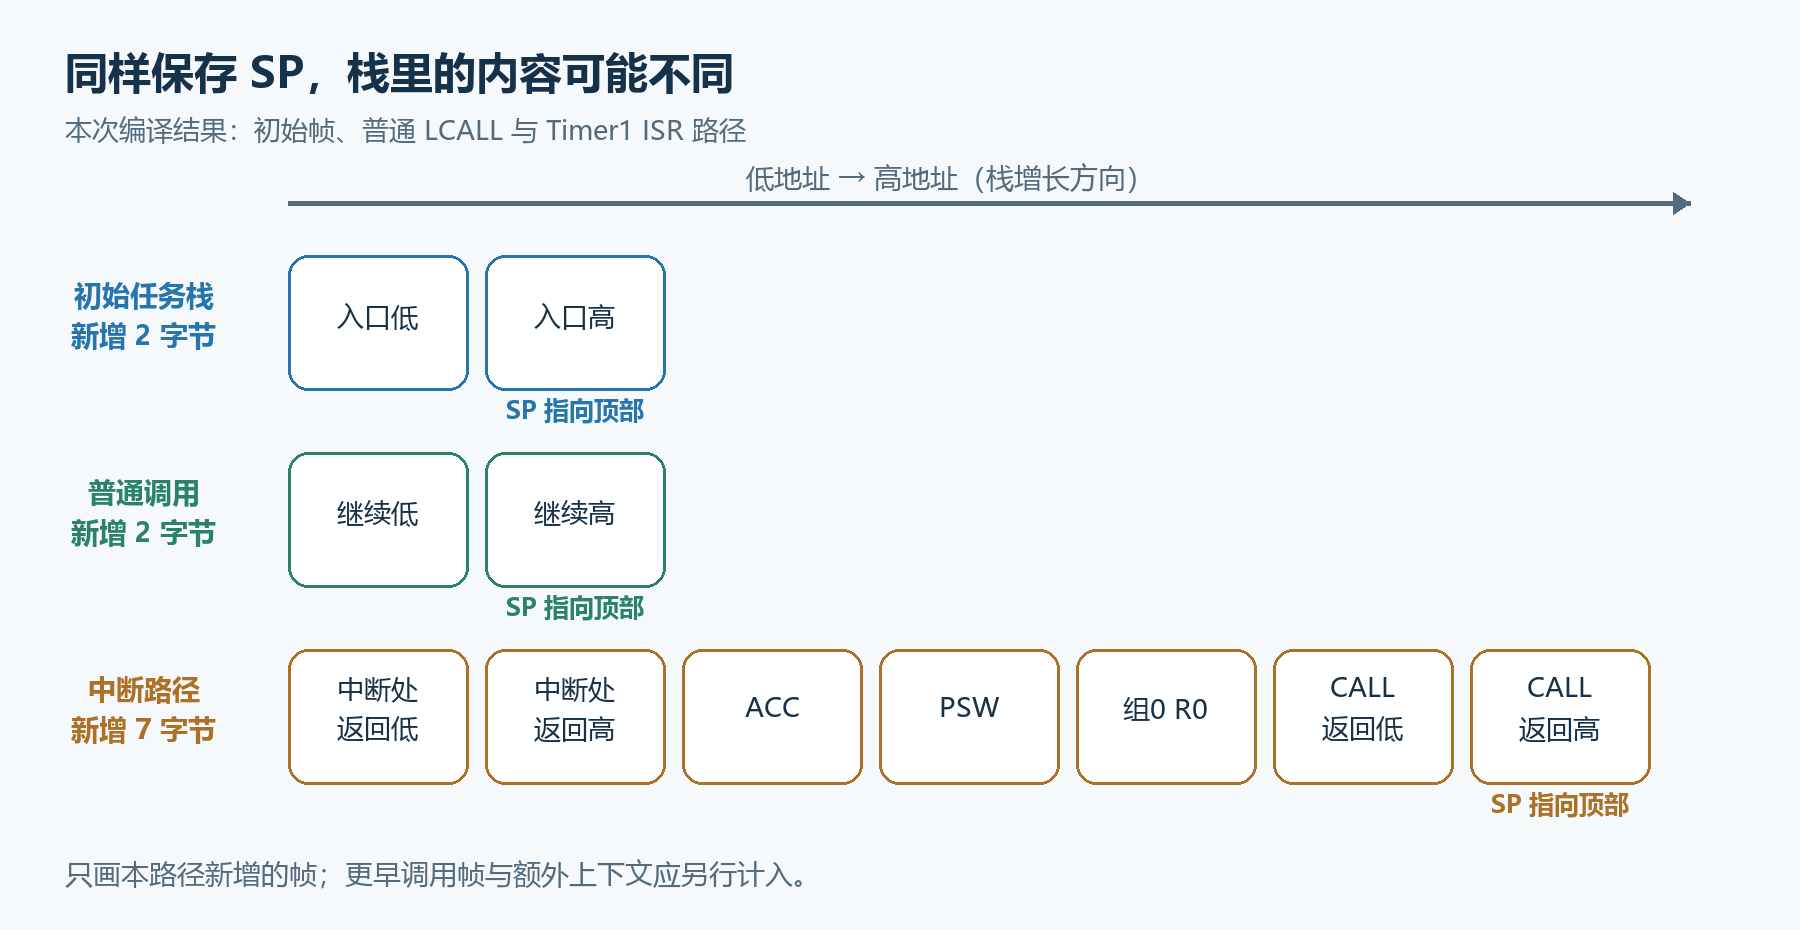

*自绘补充示意图。图中列出切换点新加入的字节，不代表栈下方没有更早的调用帧；完整任务状态可能需要更多保存项。*

| 来源 | 进入 task_switch 时本路径新增的内容 | 新增字节数 |
|---|---|---|
| task_load 初始栈 | 任务入口低、高字节 | 2 |
| 普通 LCALL | 调用后继续地址低、高字节 | 2 |
| Timer1 中断路径 | 硬件返回地址 2 字节、ACC/PSW/R0 共 3 字节、LCALL 返回地址 2 字节 | 7 |

经典中断入口首先保存被中断处的返回地址；随后本次 ISR 的指令保存寄存器，再 CALL 到切换函数。因而在这条中断路径上保存的 SP 指向的是 **LCALL 的返回地址顶部**，不是直接指向被中断处的返回地址。

若目标栈也来自这条中断路径，切换函数的 RET 会先回到 `0x020C`，让目标栈上的 POP 序列和 RETI 继续执行。若目标是初始栈或普通调用栈，RET 的目标就不同。

不同帧可以通过明确的端口设计兼容，但当前的两字节初始化和简单换 SP，并没有自动建立这种兼容协议。


## 15. 为什么换栈后还必须检查 RETI？

以下为**在 Timer1 中断实际发生条件下的补充分析**。

假设任务 A 被定时器 1 中断，ISR 调用 `task_switch`，随后换到 B 的初始栈：

```text
A 被中断 → A 栈中形成中断路径帧
task_switch 保存 A 的 SP
换到 B 初始栈 → RET 直接进入 B 入口
B 开始运行，当前路径尚未经过 ISR 的 POP 和 RETI
```

经典 8051 的 RETI 除了恢复 PC，还结束相应的中断服务状态，让中断优先级逻辑知道本次服务结束；它不是“顺便恢复所有寄存器”的指令。普通 RET 不能代替这一作用。

若切换使该 RETI 被延后到 A 再次恢复以后才执行，同级或较低级中断的受理就可能受到影响。CPU 的中断服务状态也不会因为 SP 换了，就自动成为另一任务的私有状态。

反过来，不能为了“总要结束中断”就把所有普通切换的 RET 改成 RETI。必须结合入口来源、栈结构、控制器规则和首次启动方式设计返回通道。

本次 ISR 恢复序列即使顺利执行，也只恢复了 ACC、PSW 和组 0 的 R0。要保证任意位置暂停的任务恢复，还需分析 B、DPTR、R1—R7 等状态，以及共享数据的可重入性。


## 16. 完整切换需要怎样组织保存与恢复？

以下是**补充设计框架，不是配套源码，也不是可直接烧录的修复代码**。

```text
进入约定的切换入口
  1. 在源任务栈仍然有效时，保存该入口要求的状态
  2. 确认返回位置和恢复帧已经按协议形成
  3. 保存源任务 SP
  4. 选择允许运行的目标任务
  5. 装入目标 SP
  6. 按目标帧格式逆序恢复状态
  7. 沿约定的普通返回或中断返回通道继续执行
```

保存/恢复顺序必须成对。例如自编模型先保存 `ACC、B、DPL、DPH、PSW、R0…R7`，则弹出顺序应与压入顺序相反，并正确处理 PSW 与寄存器组的关系。切换函数为计算目标而使用的寄存器，也应纳入必要的保护分析。

两个实现约束尤其重要：

- **保护要在破坏之前完成。**如果先运行会覆盖 A、PSW 的 C 代码，再去保存它们，保存的是已经改变的值。
- **换栈之后，代码必须按目标帧运行。**编译器生成的函数结尾若仍假定源调用帧存在，就可能从目标栈弹出错误数据。

因此，实际端口往往需要受控的汇编入口、恢复入口，以及对编译器生成结果的检查。简单在某个 C 函数中间加若干 PUSH/POP，不能自动解决所有调用约定和中断问题。


## 17. 增加保护后，初始化帧和栈预算也要更新

原配套 `task_load` 只构造了任务入口的两个字节，这是与“下一步 RET 直接取入口”的路径配套的。

**补充例子：**假设一个自编恢复协议会先恢复经典模型的 13 个单字节寄存器值，即 ACC、B、DPL、DPH、PSW 和 R0—R7，然后再用两字节地址返回：

| 项目 | 示例所需空间 |
|---|---|
| 两字节返回地址 | 2 字节 |
| 13 项单字节寄存器值 | 13 字节 |
| 这一简化恢复帧合计 | 15 字节 |

这只是预算例子，不是当前包的帧，也不包含所有增强内核状态。若入口还有额外 CALL、保存项或软件栈，实际要求会更多。

第一次进入任务时，栈必须也包含该恢复通道期待的格式和初始值。否则它会先 POP 并不存在的寄存器值，把入口地址字节当成寄存器内容，最后再取到错误返回地址。

源码每个任务栈为 32 字节。若采用更大的帧，必须重新计算最深调用链、保存开销、中断嵌套与恢复路径；不能沿用“原来例子分了 32 字节，所以足够”的结论。


## 18. 用不同寄存器组是否就能隔离任务？

以下为**补充理解与本次内存布局分析**。

8051 有四组 R0—R7，PSW 的 RS1、RS0 选择当前组。给不同执行路径安排不同组，有时能减少部分通用寄存器的保存，但 ACC、B、DPTR 等并不会因此自动各有一份。

本次链接表只为寄存器组 0 预留 `0x00—0x07`，其他相关布局为：

| 对象 | 本次地址 |
|---|---|
| `task_id` | 内部 RAM `0x08` |
| `tasks` | 内部 RAM `0x09—0x14` |
| `task_stack` | 内部 RAM `0x15—0x54` |
| `task_sp` | 内部 RAM `0x55—0x56` |

寄存器组 1 使用 `0x08—0x0F`，在这个布局中与 `task_id` 和部分 `tasks` 存储重叠。因此，不能只给 ISR 加一个 `using 1` 或随意改 PSW，就认为已经解决了上下文问题。

使用额外寄存器组时，要让链接布局确实保留对应区域，处理 PSW 的保存恢复，并确认直接地址 PUSH/POP 指向正确的组。重入数据、共享外设和其他寄存器仍需单独分析。


## 19. 切换临界区与初始化时序

以下为**补充工程原则**。

任务编号、保存 SP 和硬件 SP 是一组相关状态。若抢占调度能在它们更新过程中再次进入，可能出现“编号属于 B，栈还属于 A”的组合。需要通过合适的中断屏蔽、优先级规则或专门入口保证关键更新不会被不允许的调度重入打断。

管理临界区还要考虑：

- 保留原先的中断允许状态；原本关闭时，不应退出临界区就无条件打开。
- 如果临界区中允许换任务，恢复中断状态的代码属于哪项任务、何时执行，需要明确设计。
- 关中断时间应受控，避免把耗时外设操作或长等待放进关键区。
- `volatile` 可用于表达异步可见的数据访问要求，但它不会把多条操作变成原子动作，也不会保存任务寄存器。

配套 `main` 先调用 `Timer0_init`、`Timer1_Init`，随后才 `task_load` 两个任务并装入首个 SP。更稳妥的设计思路是先完成任务数据、初始帧及调度入口准备，再允许相关中断按约定进入；实际启用顺序仍须与器件、启动代码和移植层匹配。

这里只指出切换与启动的约束，不擅自把笔记中的补充原则当作已验证内核实现。


## 20. 调试时怎样分别验证选择和恢复？

以下为**补充验证方法，尚未在本环境执行**。

| 检查层次 | 观察对象 | 应确认的关系 |
|---|---|---|
| 选择规则 | `task_id` | 编号在有效范围内，符合预期顺序 |
| 栈记录 | SP、`task_sp` | 保存源任务位置，恢复目标任务位置 |
| 控制流 | CALL 后地址、RET/RETI 目标 | 首次进入口，后续回正确的继续位置 |
| 寄存器 | A、B、PSW、DPTR、R0—R7 | 恢复任务所依赖的值没有混入另一任务 |
| 数据存储 | 参数区、局部数据、共享对象 | 任务交错没有破坏仍活动的数据 |
| 中断协议 | 向量、允许位、返回路径、优先级 | 中断确实启用且服务状态按协议结束 |
| 栈空间 | 栈边界、填充标记、最深调用路径 | 没有越界或互相覆盖 |

建议按由简单到复杂的顺序观察：

1. 先检查任务初始化帧与普通调用切换，确认地址机制。
2. 为每项任务设计能在恢复后检查的中间状态，结合反汇编确认它们实际位于哪些寄存器或区域。
3. 再分析被允许的中断切换入口、保存帧和 RETI 路径。
4. 最后检查嵌套、任务等待、最坏栈深与调度重入。

单纯看到两个 LED 都在闪，只能证明某些路径执行了；它不能覆盖所有寄存器、暂停点或返回帧。C 级测试也可能把变量优化为常量或放到别处，应根据生成代码判断测试到底覆盖了什么。


## 21. 一页复习与常见误解

| 知识点 | 本篇应掌握的结论 |
|---|---|
| 调度策略 | 本例按任务编号轮转，没有在切换函数中筛选就绪任务 |
| 切换顺序 | 先保存源 SP，再选择目标并恢复目标 SP |
| 运行时间 | 协作路径的编号交替不保证固定时间片 |
| 继续位置 | 普通 CALL 已保存调用后的地址，初始帧则保存入口 |
| 上下文 | 正确地址之外，还要恢复后续执行依赖的状态 |
| 本次 task_switch | 改写 A、R0 和相关标志，没有独立的完整保存序列 |
| C51 局部变量 | 可能在寄存器或固定存储区，不自动属于任务私有栈 |
| Timer1 ISR | 本次自动保存 ACC、PSW、组0的R0，末尾使用 RETI |
| 中断启用 | 初始化中没有开启 ET1，计数启动不等于中断已启用 |
| 帧格式 | 初始栈、普通调用、中断路径具有不同结构 |
| RETI | 处理中断返回协议，不自动恢复全部寄存器 |
| 寄存器组 | 需要真实内存预留，且不能替代全部上下文保护 |
| 初始帧 | 必须与恢复入口期待的格式匹配 |
| 验证范围 | 包内已有编译结果不等于本篇完成运行验证 |

| 常见说法 | 更准确的理解 |
|---|---|
| “保存 SP 就保存全部上下文” | SP 只指向栈，栈里究竟有哪些保存项要检查 |
| “ISR 自动保护了，所以换任务也安全” | 普通 ISR 保护和任务完整恢复的边界不同 |
| “改成 RETI 就能解决” | 返回指令必须与入口、帧格式和中断协议配套 |
| “换一个寄存器组就行” | 还需保留对应 RAM，保护共享寄存器与其他数据 |
| “两个 LED 能闪就说明内核正确” | 仍需验证中间状态、栈边界和中断返回路径 |


## 22. 自测与参考答案

1. 为什么保存当前 SP 必须在修改 `task_id` 之前？
2. `MAX_TASKS=2` 时，编号 1 的下一项是什么？
3. 两个任务严格交替，是否说明两者都得到相同 CPU 时间？
4. 本例 `task_switch` 是否会跳过 `TASK_SUSPENDED` 的任务？
5. task0 在 `0x01AE` 执行三字节 LCALL 后，保存的继续地址是什么？
6. 本次 `task_switch` 的生成代码会覆盖哪两个主要数据寄存器？
7. 为什么低字节计算完成后的 CY 也可能属于任务上下文？
8. `Delay1000ms` 的 i、j、k 在本次编译里分别对应什么？
9. 本次 Timer1 ISR 软件保存了哪些项？它是否保存了 R1—R7？
10. Timer1 路径从硬件中断到切换函数，本路径新增了多少栈字节？
11. 为什么从 ISR 内换到初始任务栈后，只执行 RET 还不能说明中断服务已经结束？
12. 定时器 1 初始化已执行 `TR1=1`，是否就能证明周期抢占已经工作？
13. 本次布局为什么不能随意使用寄存器组 1？
14. 若恢复入口先 POP 13 个寄存器值，再取两字节返回地址，初始化帧能否仍只有两个字节？

### 参考答案

1. 当前编号必须仍标识源任务，否则会把源 SP 写进目标任务记录。
2. 加一得到 2，再回绕到 0。
3. 不能。协作路径的运行长度由让出时机决定。
4. 不会。综合例子由任务自己检查挂起状态并再次让出。
5. `0x01B1`，低字节 `0xB1`、高字节 `0x01`。
6. A/ACC 和 R0；运算还会影响 PSW 中的相关标志。
7. 高字节 ADDC 等后续运算可能依赖这个进位，丢失会改变结果。
8. 组0的 R7、R6、R5，对应内部地址 `0x07`、`0x06`、`0x05`。
9. ACC、PSW 和组0的R0；没有保存 R1—R7。
10. 7 字节：硬件返回地址2、三个保存字节、LCALL返回地址2；不包括已有的更早调用帧。
11. RET 不完成 RETI 的中断服务结束协议；ISR 的恢复尾部可能尚未执行。
12. 不能。还需对应允许位等条件；所读初始化没有开启 ET1。
13. 组1的 `0x08—0x0F` 与 `task_id`、部分 `tasks` 存储重叠，需重新预留和布局。
14. 不能。必须按该恢复协议构造匹配帧，这个简化模型至少需要15字节。

### 自编综合判断题

“我把每个任务栈扩大到 64 字节，给 ISR 声明 `using 1`，并把 `task_switch` 的结尾改为 RETI，所以任意位置的任务切换都正确了。”这个判断缺了哪些依据？

**参考思路：**扩大栈只影响容量，不能保证帧格式正确；组1需预留内存且不能保护全部共享寄存器；RETI要与中断入口及返回协议配套；还要检查初始化帧、保存恢复顺序、C51重入数据、调度临界区和实际生成代码，并进行相应运行验证。


## 23. 来源、五篇规划与下一篇

课程来源：[《自己动手写嵌入式操作系统》网盘资料](https://pan.baidu.com/s/1BaPETt4F3Xnew179lHT4DA?pwd=9988)，提取码 `9988`。

| 本篇内容 | 证据或说明 |
|---|---|
| 视频14—15的主题 | 已核对网盘目录标题 |
| 任务选择、换SP、任务主动调用、ISR定义 | 配套 `os_demo/main.c` |
| 符号地址、寄存器组及数据布局 | 包内 `Listings/project.m51` |
| 编译器版本、静态覆盖信息 | 包内 `Listings/main.lst` |
| task_switch 与 Timer1 ISR 的实际指令 | 包内 `Objects/project.hex`，已检查对应记录校验和和字节 |
| 工程目标 | `project.uvproj` 的 STC8H8K64U Series |
| 图示、进位故障、完整切换框架与调试建议 | 自绘和补充说明，不是视频逐字内容或已验证修复 |

| 编号 | 笔记 | 对应视频 |
|---|---|---|
| 01 | [操作系统基础、多任务与资源调度](01-操作系统基础、多任务与资源调度.ipynb) | 01—08 |
| 02 | [STC内存、任务堆栈与任务切换原理](02-STC内存、任务堆栈与任务切换原理.ipynb) | 09—13 |
| 03 | 任务调度器与上下文保护 | 14—15 |
| 04 | 多任务外设访问与延时问题 | 16—17 |
| 05 | sleep实现与定时时间片轮转 | 18—19 |

下一篇继续分析两个任务怎样操作外设，以及为什么程序里写的“延时1秒”不一定等于真实经过1秒。第05篇再展开等待状态、硬件计时与定期调度。
